In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Import the necessary helper functions and path constants
from data.dataloader import load_all_datasets
from data.preprocessing import complete_data_preprocessing
from scipy import stats
from scipy.stats import mannwhitneyu

### 1. Configuration and Targeted Data Loading

In [2]:
# Define the channel and observation window for the initial test
TEST_CHANNEL_ID = 'UCBJuEqXfXTdcPSbGO9qqn1g'
OBSERVATION_WEEKS = 52 # 1 year

# Use the managed subset size for efficient loading
subset_size = 5000000 
print(f"Loading datasets with subset_size={subset_size}...")

channels_df, videos_df, timeseries_df, num_comments_df = load_all_datasets(subset_size=subset_size, compressed_videos=False)
print("Raw data loading complete.")

Loading datasets with subset_size=5000000...
Raw data loading complete.


### 2. Preprocessing and Merging

In [3]:
print("\nApplying preprocessing and merging (channels and timeseries)...")
videos_metadata_df, timeseries_df_processed = complete_data_preprocessing(channels_df, videos_df, timeseries_df, num_comments_df)

# Use a copy for clarity
df_ts = timeseries_df_processed.copy()
df_ts.name = 'df_timeseries_subset'
df_videos = videos_metadata_df.copy() 
df_videos.name = 'df_videos_subset'
print(f"Total processed time-series records: {len(df_ts):,}")
print(f"Total processed video records: {len(df_videos):,}")


Applying preprocessing and merging (channels and timeseries)...
Merging timeseries with channels data...
Merging videos metadata with number of comments...
Preprocessing videos metadata with number of comments included...
Total processed time-series records: 5,000,000
Total processed video records: 5,000,000


### 3. Filtering and Time Window Selection

In [4]:
# Filter for the specific test channel
channel_ts = df_ts[df_ts['channel'] == TEST_CHANNEL_ID]

print(f"Records for test channel '{TEST_CHANNEL_ID}': {len(channel_ts)}")

# Check for existence and select the time window
if channel_ts.empty:
    print(f"ERROR: Test channel '{TEST_CHANNEL_ID}' not found in the subset of {subset_size} records.")
    # Exit analysis early
    exit()

if len(channel_ts) < OBSERVATION_WEEKS:
    print(f"Warning: Channel has only {len(channel_ts)} weeks, less than the {OBSERVATION_WEEKS} required. Using all available data.")
    final_window = channel_ts
else:
    # Select the latest 52 weeks (1 year) of data
    final_window = channel_ts.tail(OBSERVATION_WEEKS)
    print(f"Successfully isolated the latest {len(final_window)} weeks (1 year) of data.")

# Display the date range for confirmation
print(f"Data window spans from {final_window['datetime'].min().date()} to {final_window['datetime'].max().date()}")
print("-" * 50)

Records for test channel 'UCBJuEqXfXTdcPSbGO9qqn1g': 117
Successfully isolated the latest 52 weeks (1 year) of data.
Data window spans from 2018-10-01 to 2019-09-23
--------------------------------------------------


### 4. Stability Metrics Calculation (Coefficient of Variation)

In [5]:
def calculate_cv(data_series):
    """Calculates the Coefficient of Variation (CV = Std Dev / Mean)."""
    mean = data_series.mean()
    std = data_series.std()
    
    # Check is crucial: If mean is 0, growth is perfectly stable (zero), CV is NaN/Inf.
    # We return np.nan to explicitly mark this edge case.
    return np.nan if mean == 0 else std / mean

# --- Calculate CV for Views ---
delta_views = final_window['delta_views']
cv_views = calculate_cv(delta_views)

# --- Calculate CV for Subscribers ---
delta_subs = final_window['delta_subs']
cv_subs = calculate_cv(delta_subs)

### 5. Results and Validation for Test Channel

--- Stability Metrics for Test Channel ---
Channel ID: UCBJuEqXfXTdcPSbGO9qqn1g
Observation Period: 52 weeks
--------------------------------------------------
Mean Weekly Views Gain (μ): 127,298.85
CV for Views Gain (S_views): 1.8041
Mean Weekly Subscriber Gain (μ): 252.38
CV for Subscriber Gain (S_subs): 1.4339
--------------------------------------------------


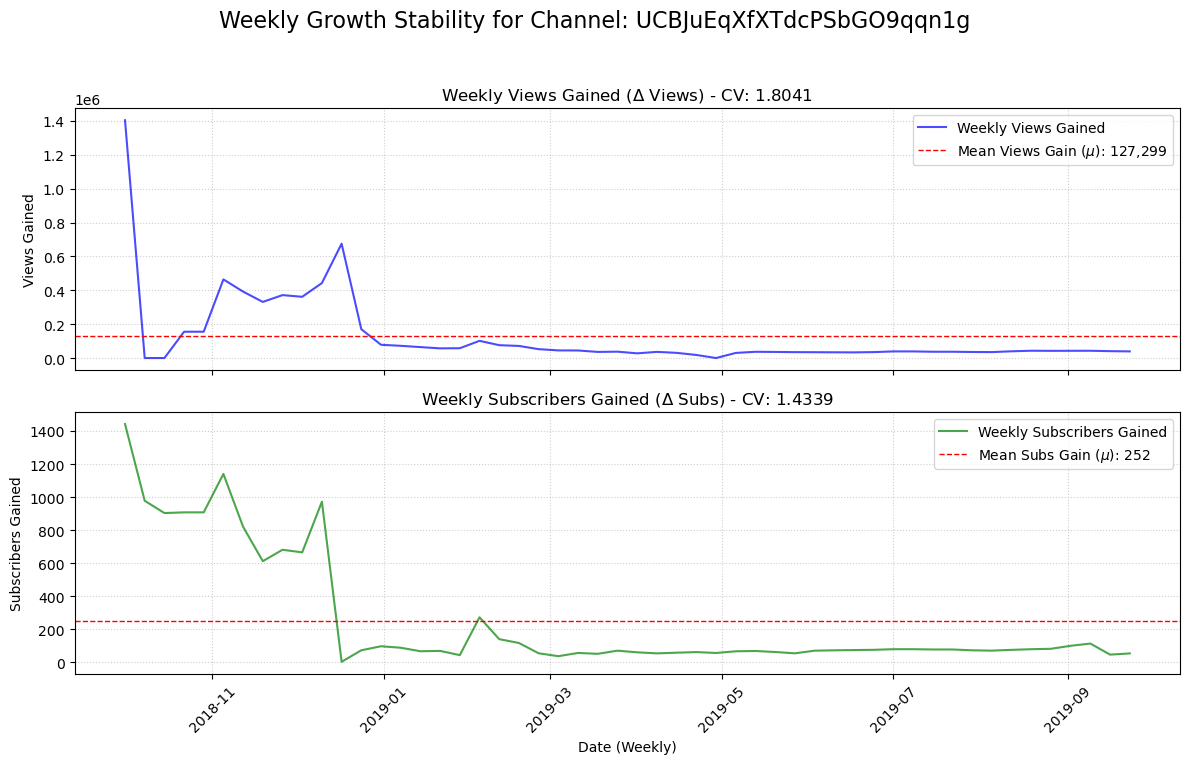

In [6]:
# --- 5.1 Print Summary Metrics ---
print("--- Stability Metrics for Test Channel ---")
print(f"Channel ID: {TEST_CHANNEL_ID}")
print(f"Observation Period: {len(final_window)} weeks")
print("-" * 50)
print(f"Mean Weekly Views Gain (μ): {delta_views.mean():,.2f}")
print(f"CV for Views Gain (S_views): {cv_views:.4f}")
print(f"Mean Weekly Subscriber Gain (μ): {delta_subs.mean():,.2f}")
print(f"CV for Subscriber Gain (S_subs): {cv_subs:.4f}")
print("-" * 50)


# --- 5.2 Visualization ---
# Set up a 2-panel figure for clear comparison
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(12, 8), sharex=True)
fig.suptitle(f'Weekly Growth Stability for Channel: {TEST_CHANNEL_ID}', fontsize=16)

# --- Plot 1: Weekly Views Gain (Delta Views) ---
axes[0].plot(final_window['datetime'], final_window['delta_views'], label='Weekly Views Gained', color='blue', alpha=0.7)
axes[0].axhline(delta_views.mean(), color='red', linestyle='--', linewidth=1, label=rf'Mean Views Gain ($\mu$): {delta_views.mean():,.0f}')

axes[0].set_title(rf'Weekly Views Gained ($\Delta$ Views) - CV: {cv_views:.4f}')
axes[0].set_ylabel('Views Gained') 
# axes[0].set_yscale('log') # # Use a log scale if the data is highly skewed
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

# --- Plot 2: Weekly Subscriber Gain (Delta Subs) ---
axes[1].plot(final_window['datetime'], final_window['delta_subs'], label='Weekly Subscribers Gained', color='green', alpha=0.7)
axes[1].axhline(delta_subs.mean(), color='red', linestyle='--', linewidth=1, label=rf'Mean Subs Gain ($\mu$): {delta_subs.mean():,.0f}')

axes[1].set_title(rf'Weekly Subscribers Gained ($\Delta$ Subs) - CV: {cv_subs:.4f}')
axes[1].set_xlabel('Date (Weekly)')
axes[1].set_ylabel('Subscribers Gained')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)


plt.xticks(rotation=45) # Rotate date labels for readability
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to make room for suptitle
plt.show()

### 6. Comparative Stability Analysis: Outperformer vs. Control

In [7]:
print("\n--- Starting Group Comparative Analysis ---")

# --- Step A: Calculate Mean Engagement Efficiency for Each Channel ---
# We compute the average engagement efficiency across all videos for each channel.
# This gives us the overall Outperformer/Control metric for RQ1 (as a proxy).
channel_efficiency = df_videos.groupby('channel_id')['engagement_efficiency'].mean().reset_index()
channel_efficiency.columns = ['channel', 'mean_efficiency'] # each row represents a channel, along with its overall engagement performance score

# Filter out NaNs and infs if any exist after cleaning
channel_efficiency = channel_efficiency.dropna()

# Print basic stats
print(f"Source Data: {df_videos.name}")
print(f"Total channels processed: {len(df_videos['channel_id'].unique()):,}")
print(f"Total channels with valid engagement efficiency: {len(channel_efficiency):,}")
print(f"Engagement Efficiency - Mean: {channel_efficiency['mean_efficiency'].mean():.4f}, Median: {channel_efficiency['mean_efficiency'].median():.4f}")


--- Starting Group Comparative Analysis ---
Source Data: df_videos_subset
Total channels processed: 9,394
Total channels with valid engagement efficiency: 9,393
Engagement Efficiency - Mean: 0.0353, Median: 0.0279


In [8]:
# --- Step B: Define Outperformer and Control Groups (Proxy Definition) ---
# We use the top 10% for Outperformers and the bottom 10% for the Control Group 
# based on mean_efficiency. This is a PROXY for the full RQ1 method.
OUTPERFORMER_PCT = 0.90
CONTROL_PCT = 0.10

outperformers_id = channel_efficiency[
    channel_efficiency['mean_efficiency'] >= channel_efficiency['mean_efficiency'].quantile(OUTPERFORMER_PCT)
]['channel'].tolist()

control_group_id = channel_efficiency[
    channel_efficiency['mean_efficiency'] <= channel_efficiency['mean_efficiency'].quantile(CONTROL_PCT)
]['channel'].tolist()

print(f"Outperformer Group Size (Top {100 - OUTPERFORMER_PCT * 100:.0f}%): {len(outperformers_id):,}")
print(f"Control Group Size (Bottom {CONTROL_PCT * 100:.0f}%): {len(control_group_id):,}")
print("-" * 50)

Outperformer Group Size (Top 10%): 940
Control Group Size (Bottom 10%): 940
--------------------------------------------------


In [9]:
# --- Step C: Calculate Stability (CV) for All Relevant Channels ---
YEAR_PERCENTAGE = 0.5
WEEKS = OBSERVATION_WEEKS * YEAR_PERCENTAGE

# 1. Group the time-series data by channel
ts_grouped = df_ts.groupby('channel')

# 2. Define the rolling/fixed window CV calculation function
def calculate_channel_cvs(group):
    # Only use the latest OBSERVATION_WEEKS (52) weeks if available
    analysis_window = group.tail(OBSERVATION_WEEKS)
    
    if len(analysis_window) < OBSERVATION_WEEKS * YEAR_PERCENTAGE: # Require at least 1 year of data
        return pd.Series([np.nan, np.nan], index=['cv_views', 'cv_subs'])

    cv_views = calculate_cv(analysis_window['delta_views'])
    cv_subs = calculate_cv(analysis_window['delta_subs'])
    
    return pd.Series([cv_views, cv_subs], index=['cv_views', 'cv_subs'])

# 3. Apply the CV calculation to all channels that have enough data
# This step is computationally intensive, so running on a subset is wise.
print("Calculating CV for all channels with sufficient time-series data...")
all_channel_cvs = ts_grouped.apply(calculate_channel_cvs, include_groups=False) \
                            .rename_axis('channel') \
                            .reset_index()

print(f"Source Data: {df_ts.name}")
print(f"Total channels with computed CVs: {len(all_channel_cvs.dropna()):,}")

Calculating CV for all channels with sufficient time-series data...
Source Data: df_timeseries_subset
Total channels with computed CVs: 34,032


In [10]:
# --- Step D: Comparative Analysis ---
MINIMUM_SAMPLES = 20 # Minimum valid samples per group to run the test
THRESHOLD_ALPHA = 0.05

# Merge CVs with the Outperformer/Control groups
outperformers_cv = all_channel_cvs[all_channel_cvs['channel'].isin(outperformers_id)].dropna()
control_cv = all_channel_cvs[all_channel_cvs['channel'].isin(control_group_id)].dropna()

print(f"Channels found in both the video-based groups AND the time-series CV calculations.")
print(f"Final Outperformer N: {len(outperformers_cv):,}")
print(f"Final Control N: {len(control_cv):,}")

# Mean CVs for reference
mean_cv_views_outperformers = outperformers_cv['cv_views'].mean()
mean_cv_views_control = control_cv['cv_views'].mean()
mean_cv_subs_outperformers = outperformers_cv['cv_subs'].mean()
mean_cv_subs_control = control_cv['cv_subs'].mean()

print(f"Mean CV_Views - Outperformers: {mean_cv_views_outperformers:.4f}, Control: {mean_cv_views_control:.4f}")
print(f"Mean CV_Subs - Outperformers: {mean_cv_subs_outperformers:.4f}, Control: {mean_cv_subs_control:.4f}")

Channels found in both the video-based groups AND the time-series CV calculations.
Final Outperformer N: 226
Final Control N: 231
Mean CV_Views - Outperformers: 0.9089, Control: 0.7119
Mean CV_Subs - Outperformers: 1.2986, Control: 0.8228


#### Statistical Test (Outperformer vs. Control)

To be included in the final test, a channel must satisfy three conditions simultaneously:
   - It must be in the video subset to have a mean_efficiency score
   - It must be in the top/bottom X% of that small group to be an Outperformer/Control
   - It must be one of the channels that has at least OBSERVATION_WEEKS of contiguous data (a very strict filter) in the time-series subset.

In [11]:


if len(outperformers_cv) > MINIMUM_SAMPLES and len(control_cv) > MINIMUM_SAMPLES: # Ensure enough samples for test
    # Perform Mann-Whitney U test on CV_Views
    stat_v, p_v = mannwhitneyu(outperformers_cv['cv_views'], control_cv['cv_views'], alternative='greater') # Alternative='less' tests the hypothesis that Outperformers (Group 1) have a lower CV (less volatile) than the Control Group (Group 2).

    # Perform Mann-Whitney U test on CV_Subs
    stat_s, p_s = mannwhitneyu(outperformers_cv['cv_subs'], control_cv['cv_subs'], alternative='greater')

    print("\n--- Statistical Test Results (Mann-Whitney U Test) ---")
    print("Hypothesis: Outperformers have significantly HIGHER CV (More Volatile Growth)")
    print("-" * 50)
    print(f"CV_Views Test P-Value: {p_v:.4f} (Views Stability)")
    print(f"CV_Subs Test P-Value: {p_s:.4f} (Subscriber Stability)")
    
    if p_v < THRESHOLD_ALPHA:
        print("Views Result: STATISTICALLY SIGNIFICANT. Outperformers are LESS views-stable (MORE volatile).")
    else:
        print("Views Result: NOT SIGNIFICANT. No strong evidence of views-stability difference.")
        
    if p_s < THRESHOLD_ALPHA:
        print("Subs Result: STATISTICALLY SIGNIFICANT. Outperformers are LESS subscriber-stable (MORE volatile).")
    else:
        print("Subs Result: NOT SIGNIFICANT. No strong evidence of subscriber-stability difference.")
else:
    print("\nWarning: Not enough valid channels in groups (N<20) to run a reliable statistical test.")


--- Statistical Test Results (Mann-Whitney U Test) ---
Hypothesis: Outperformers have significantly HIGHER CV (More Volatile Growth)
--------------------------------------------------
CV_Views Test P-Value: 0.0003 (Views Stability)
CV_Subs Test P-Value: 0.0000 (Subscriber Stability)
Views Result: STATISTICALLY SIGNIFICANT. Outperformers are LESS views-stable (MORE volatile).
Subs Result: STATISTICALLY SIGNIFICANT. Outperformers are LESS subscriber-stable (MORE volatile).


Comment: Since both P-values (0.0003 and 0.0000) are far less than the common significance threshold (α=0.05), we statistically reject the null hypothesis (H0​) that there is no difference in stability.